In [ ]:
import folium
import pandas as pd
import matplotlib.pyplot as plt
import emeval.input.spec_details as eisd
import emeval.input.phone_view as eipv
from transit_matching.matching import get_graph_match, get_transit_match
from transit_matching.analysis_helper import create_tasks

In [12]:
def plot_path(path, df):
    locations = df[['latitude', 'longitude']]
    locations = locations.to_numpy()
    
    m = folium.Map(location=path[0], zoom_start=15)
    folium.PolyLine(
        locations=path,
        color='red',
        weight=5,
        opacity=0.8
    ).add_to(m)

    for i in range(len(locations)):
        folium.CircleMarker(
            location=[locations[i][0], locations[i][1]],
            radius=1
        ).add_to(m)

    display(m)

In [13]:
NON_TRANSIT_ERROR_FACTOR = 1.7
TRANSIT_ERROR_FACTOR = 1
MODERN_ERROR_FACTOR = 1.2

mode_name_map = {0: 'CAR', 1: 'BIKE', 2: 'WALK'}

def choose_best(df, map_data, non_transit_mode):
    nx_map = map_data['nx_maps'][non_transit_mode]
    best_mode = mode_name_map[non_transit_mode]
    best_error, best_path, best_distances = get_graph_match(df, nx_map)
    best_error *= NON_TRANSIT_ERROR_FACTOR
    modern = True

    if non_transit_mode != 0:
        return (best_error, best_path, best_mode, modern, best_distances)
    
    error_transit, path_transit, mode_transit, distances_transit = get_transit_match(df, map_data['historic'])
    error_modern_transit, path_modern_transit, mode_modern_transit, distances_modern_transit =  get_transit_match(df, map_data['modern'])
    error_modern_transit *= MODERN_ERROR_FACTOR

    if error_modern_transit < best_error:
        best_error, best_path, best_mode, best_distances = error_modern_transit, path_modern_transit, mode_modern_transit, distances_modern_transit

    if error_transit < best_error:
        best_error, best_path, best_mode, best_distances = error_transit, path_transit, mode_transit, distances_transit
        modern = False

    best_mode = best_mode.upper()

    return (best_error, best_path, best_mode, modern, best_distances)

In [ ]:
AUTHOR_EMAIL = "shankari@eecs.berkeley.edu"
DATASTORE_LOC = "bin/data/"
views = ['car_scooter_brex_san_jose', 'train_bus_ebike_mtv_ucb', 'unimodal_trip_car_bike_mtv_la']

sds = {view: eisd.FileSpecDetails(DATASTORE_LOC, AUTHOR_EMAIL, view) for view in views}
pvs = {view: eipv.PhoneView(sd) for view, sd in sds.items()}

In [ ]:
tasks = create_tasks(pvs, DATASTORE_LOC)
tasks.sort(key=lambda p: (p.view, p.trip_name, p.section_name, p.os, p.phone_number, p.evaluation_range))

After iterating over 1 entries, entry found
Found spec = Multi-modal car scooter BREX trip to San Jose
Evaluation ran from 2019-07-20T00:00:00-07:00 -> 2020-04-29T17:00:00-07:00
After iterating over 1 entries, entry found
Found spec = Multimodal multi-train, multi-bus, ebike trip to UC Berkeley
Evaluation ran from 2019-07-16T00:00:00-07:00 -> 2020-04-30T00:00:00-07:00
After iterating over 1 entries, entry found
Found spec = Round trip car and bike trip in the South Bay
Evaluation ran from 2019-07-20T00:00:00-07:00 -> 2020-04-29T17:00:00-07:00
-------------------- About to read transitions from server --------------------
Reading data for android phones
Loading transitions for phone ucb-sdb-android-1
Loading transitions for phone ucb-sdb-android-2
Loading transitions for phone ucb-sdb-android-3
Loading transitions for phone ucb-sdb-android-4
Reading data for ios phones
Loading transitions for phone ucb-sdb-ios-1
Loading transitions for phone ucb-sdb-ios-2
Loading transitions for phone u

In [15]:
print(f'VIEW: {"view".ljust(30)}PHONE: {"os-#".ljust(12)}TRIP: {"trip_name".ljust(40)}SECTION: {"section_name".ljust(40)}EVAL: ##  MODE: {"pred_mode".ljust(11)}| {"act_mode".ljust(11)}')

map_data = {}
for task in tasks:
    task.map_match(map_data, choose_best)
    print(str(task))
    

VIEW: view                          PHONE: os-#        TRIP: trip_name                               SECTION: section_name                            EVAL: ##  MODE: pred_mode  | act_mode   
VIEW: car_scooter_brex_san_jose     PHONE: android-1   TRIP: bus trip with e-scooter access          SECTION: city_bus_rapid_transit                  EVAL: 0   MODE: BUS        | BUS        
VIEW: car_scooter_brex_san_jose     PHONE: android-1   TRIP: bus trip with e-scooter access          SECTION: city_bus_rapid_transit                  EVAL: 1   MODE: BUS        | BUS        
VIEW: car_scooter_brex_san_jose     PHONE: android-1   TRIP: bus trip with e-scooter access          SECTION: city_bus_rapid_transit                  EVAL: 2   MODE: BUS        | BUS        
VIEW: car_scooter_brex_san_jose     PHONE: android-1   TRIP: bus trip with e-scooter access          SECTION: city_bus_rapid_transit                  EVAL: 3   MODE: BUS        | BUS        
VIEW: car_scooter_brex_san_jose     PHONE: an

In [16]:
actual_predicted_name_map = {'WALKING': 'WALK', 'BICYCLING': 'BIKE'}
predicted_sensed_name_map = {'ESCOOTER': 1, 'WALKING': 2, 'E_BIKE': 1, 'BICYCLING': 1, 'CAR': 0, 'BUS': 0, 'LIGHT_RAIL': 0, 'TRAIN': 0, 'SUBWAY': 0}

def is_prediction_correct(row):
    task = row[0]
    if task.actual_mode in actual_predicted_name_map:
        actual_mode = actual_predicted_name_map[task.actual_mode]
    else:
        actual_mode = task.actual_mode
    return actual_mode == task.predicted_mode

def get_section_time(row):
    task = row[0]
    return task.locations.iloc[-1]['ts'] - task.locations.iloc[0]['ts']

for task in tasks:
    if task.predicted_mode == None:
        tasks.remove(task)

def get_os(row):
    return row[0].os

def get_trip(row):
    return row[0].stripped_trip_name

def get_predicted_mode(row):
    return row[0].predicted_mode

def get_actual_mode(row):
    task = row[0]
    if task.actual_mode in actual_predicted_name_map:
        actual_mode = actual_predicted_name_map[task.actual_mode]
    else:
        actual_mode = task.actual_mode
    
    return actual_mode

def weighted_avg(group):
    weights = group['time_taken']
    values = group['is_correct']
    return (values * weights).sum() / weights.sum()

df = pd.DataFrame(tasks)
df['is_correct'] = df.apply(is_prediction_correct, axis=1)
df['time_taken'] = df.apply(get_section_time, axis=1)
df['os'] = df.apply(get_os, axis=1)
df['trip'] = df.apply(get_trip, axis=1)
df['predicted_mode'] = df.apply(get_predicted_mode, axis=1)
df['actual_mode'] = df.apply(get_actual_mode, axis=1)

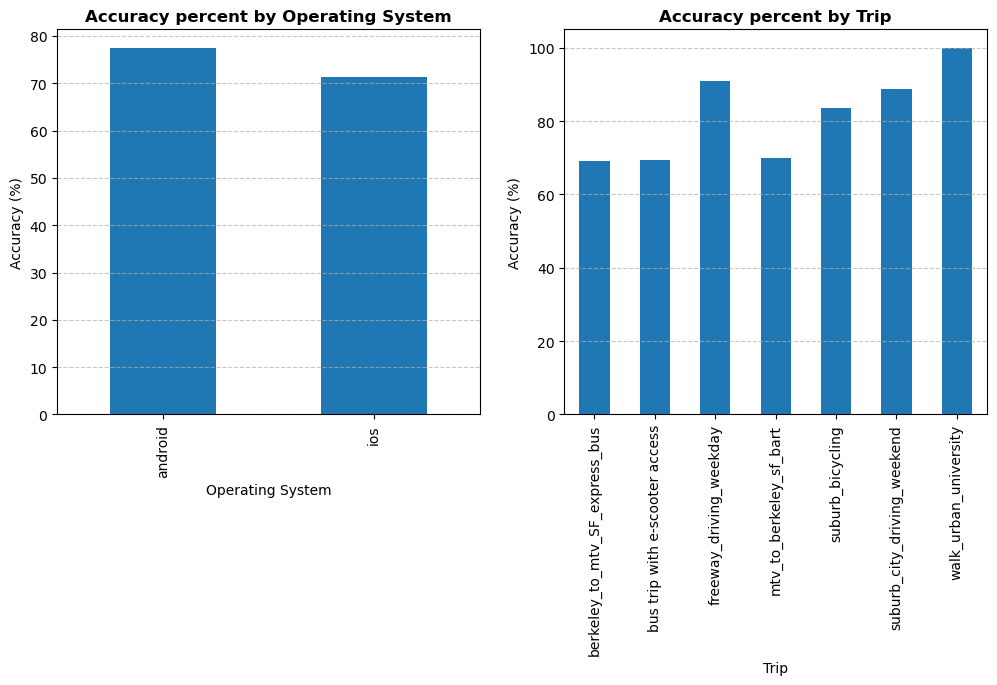

In [17]:
os_accuracy = df.groupby('os')['is_correct'].mean() * 100
trip_accuracy = df.groupby('trip')['is_correct'].mean() * 100

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
os_accuracy.plot(kind='bar', ax=axes[0])
axes[0].set_title('Accuracy percent by Operating System', fontweight='bold')
axes[0].set_xlabel('Operating System')
axes[0].set_ylabel('Accuracy (%)')
axes[0].grid(axis='y', linestyle='--', alpha=0.7)

trip_accuracy.plot(kind='bar', ax=axes[1])
axes[1].set_title('Accuracy percent by Trip', fontweight='bold')
axes[1].set_xlabel('Trip')
axes[1].set_ylabel('Accuracy (%)')
axes[1].grid(axis='y', linestyle='--', alpha=0.7)

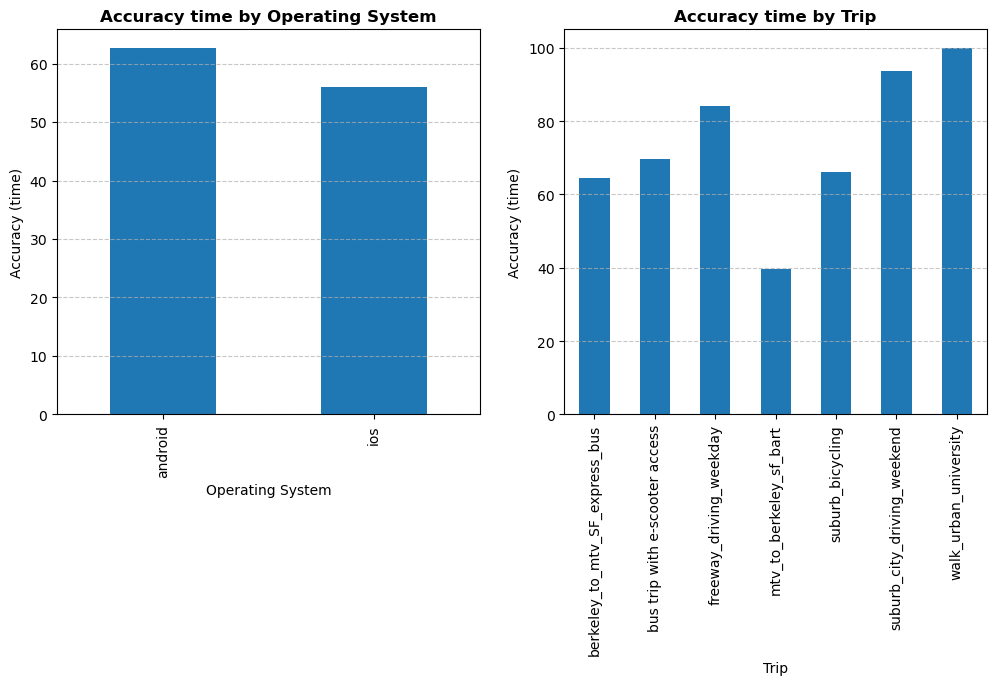

In [18]:
os_accuracy = df.groupby('os').apply(weighted_avg, include_groups=False) * 100
trip_accuracy = df.groupby('trip').apply(weighted_avg, include_groups=False) * 100

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
os_accuracy.plot(kind='bar', ax=axes[0])
axes[0].set_title('Accuracy time by Operating System', fontweight='bold')
axes[0].set_xlabel('Operating System')
axes[0].set_ylabel('Accuracy (time)')
axes[0].grid(axis='y', linestyle='--', alpha=0.7)

trip_accuracy.plot(kind='bar', ax=axes[1])
axes[1].set_title('Accuracy time by Trip', fontweight='bold')
axes[1].set_xlabel('Trip')
axes[1].set_ylabel('Accuracy (time)')
axes[1].grid(axis='y', linestyle='--', alpha=0.7)

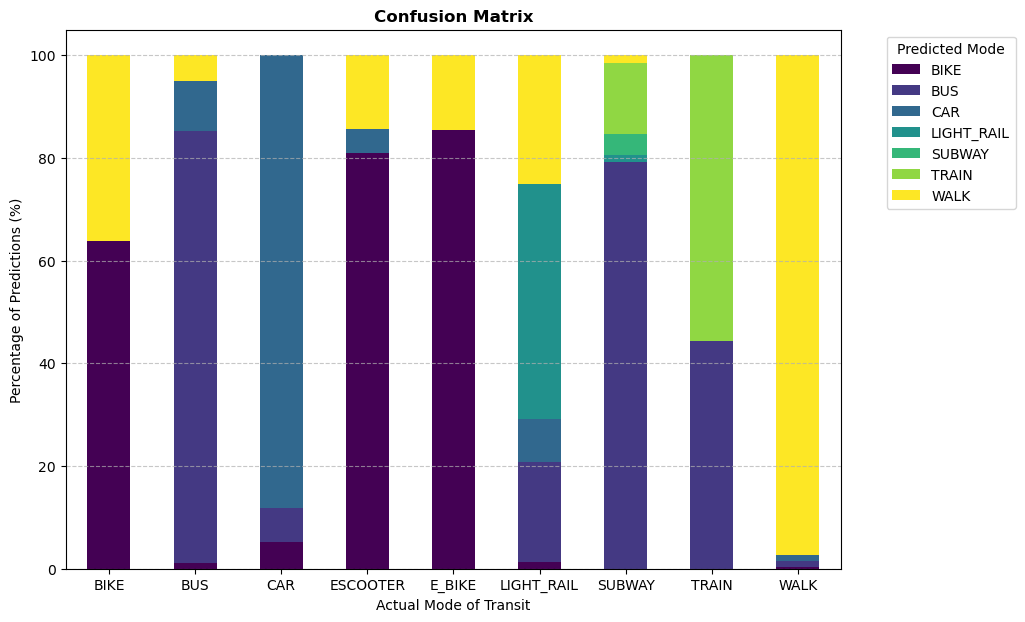

In [19]:
confusion_matrix = pd.crosstab(df['actual_mode'], df['predicted_mode'])
normalized_matrix = confusion_matrix.div(confusion_matrix.sum(axis=1), axis=0) * 100
ax = normalized_matrix.plot(kind='bar', 
                            stacked=True, 
                            figsize=(10, 7),
                            colormap='viridis')

plt.title('Confusion Matrix', fontweight='bold')
plt.ylabel('Percentage of Predictions (%)')
plt.xlabel('Actual Mode of Transit')
plt.xticks(rotation=0)
plt.legend(title='Predicted Mode', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(axis='y', linestyle='--', alpha=0.7)

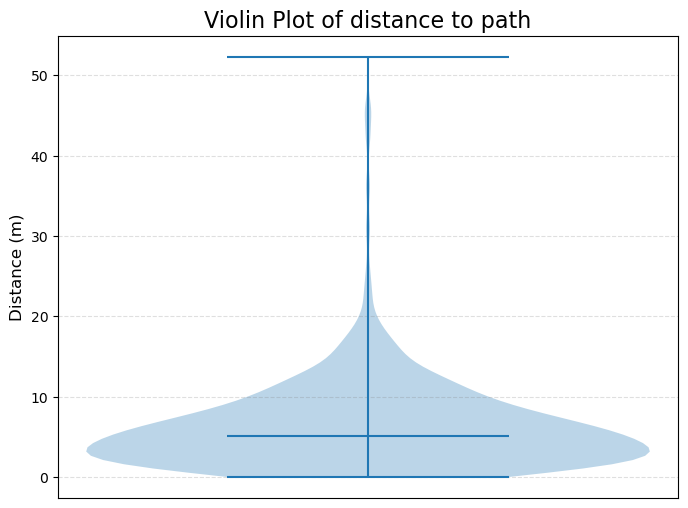

In [20]:
data_series = tasks[0].distances

fig, ax = plt.subplots(figsize=(8, 6))
violin_parts = ax.violinplot(
    data_series,
    showmeans=False,
    showmedians=True,
    showextrema=True
)

ax.set_title('Violin Plot of distance to path', fontsize=16)
ax.set_ylabel('Distance (m)', fontsize=12)

ax.set_xticks([])
ax.yaxis.grid(True, linestyle='--', which='major', color='grey', alpha=.25)